# Translation Integration

Translate transcription segments from source to target language using **argostranslate** (offline, OpenNMT-based).

Key limitation: argostranslate has **no duration budget** — the translation length is unconstrained.
Romance languages (Spanish, French, Italian) typically produce longer text than the English source,
which creates timing challenges for the downstream TTS stage.

## Setup

In [2]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

IMAGES_DIR = Path.cwd() / "images"
IMAGES_DIR.mkdir(exist_ok=True)

# Load .env (LOGFIRE_TOKEN, HF_TOKEN, etc.)
# from dotenv import load_dotenv
# load_dotenv(PROJECT_ROOT / ".env")

from foreign_whispers import FWClient

API_URL = "http://localhost:8080"
fw = FWClient(API_URL)

print(f"Project root: {PROJECT_ROOT}")
print(f"Images dir:   {IMAGES_DIR}")
print(f"SDK client ready: FWClient('{API_URL}')")

# Optional: Logfire tracing (no-op shim if unavailable)
# try:
#     import logfire
#     logfire.configure(service_name="foreign-whispers-translation")
#     print("Logfire tracing enabled.")
# except Exception:
#     class _NoopSpan:
#         def __enter__(self): return self
#         def __exit__(self, *a): pass
#     class _noop:
#         @staticmethod
#         def span(name, **kw): return _NoopSpan()
#         @staticmethod
#         def info(*a, **kw): pass
#     logfire = _noop()
#     print("Logfire not configured — using no-op shim.")

Project root: c:\Users\Bineet\Documents\nyu\Notes Spring26\Ai assignments\aiproject\foreign-whispers
Images dir:   c:\Users\Bineet\Documents\nyu\Notes Spring26\Ai assignments\aiproject\foreign-whispers\notebooks\translation_integration\images
SDK client ready: FWClient('http://localhost:8080')


## Run Translation

In [3]:
# Get video list and select the first video
videos = fw.videos()
video_id = videos[0]["id"]
print(f"Video: {videos[0]['title']} ({video_id})")

# Run translation (source EN -> target ES)
# with logfire.span("translate", video_id=video_id):
result = fw.translate(video_id)

print(f"Target language: {result['target_language']}")
print(f"Segment count:   {len(result['segments'])}")

# Show first 3 segments: EN original alongside ES translation
import json

# Load the source (English) transcription for comparison
transcription_dir = PROJECT_ROOT / "pipeline_data" / "api" / "transcriptions" / "whisper"
title = videos[0]["title"]
en_path = transcription_dir / f"{title}.json"
en_data = json.loads(en_path.read_text())
en_segs = en_data["segments"]
es_segs = result["segments"]

print("\nFirst 3 segments (EN -> ES):")
print("-" * 80)
for i, (en, es) in enumerate(zip(en_segs[:3], es_segs[:3])):
    print(f"Segment {i}:")
    print(f"  EN: {en['text'].strip()}")
    print(f"  ES: {es['text'].strip()}")
    print()

Video: Strait of Hormuz disruption threatens to shake global economy (GYQ5yGV_-Oc)
Target language: es
Segment count:   170

First 3 segments (EN -> ES):
--------------------------------------------------------------------------------
Segment 0:
  EN: 60 Minutes overtime.
  ES: 60 minutos horas extra.

Segment 1:
  EN: What's the worst case scenario that
  ES: ¿Cuál es el peor escenario?

Segment 2:
  EN: you're worried about is that it is
  ES: Te preocupa que sea



## Analyze Translation Length

Compare character counts between source and target segments.
Romance languages tend to produce longer text than English,
which matters for TTS duration budgets downstream.

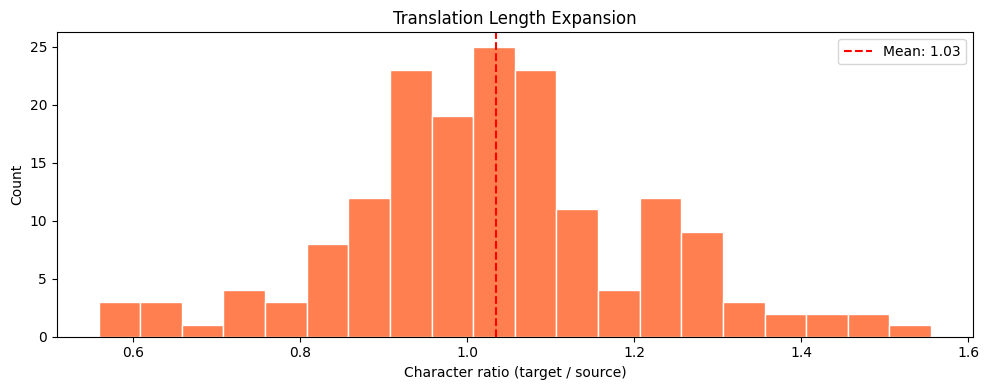

Mean ratio:   1.03
Median ratio: 1.03
Max ratio:    1.56


In [4]:
import matplotlib.pyplot as plt
import numpy as np

# Load source and target transcripts
transcription_dir = PROJECT_ROOT / "pipeline_data" / "api" / "transcriptions" / "whisper"
translation_dir = PROJECT_ROOT / "pipeline_data" / "api" / "translations" / "argos"

title = videos[0]["title"]
en_data = json.loads((transcription_dir / f"{title}.json").read_text())
es_data = json.loads((translation_dir / f"{title}.json").read_text())

en_segs = en_data["segments"]
es_segs = es_data["segments"]

# Compute char_ratio = len(es_text) / len(en_text) for each segment
ratios = [len(es["text"]) / max(len(en["text"]), 1) for en, es in zip(en_segs, es_segs)]

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(ratios, bins=20, color="coral", edgecolor="white")
ax.axvline(np.mean(ratios), color="red", linestyle="--", label=f"Mean: {np.mean(ratios):.2f}")
ax.set_xlabel("Character ratio (target / source)")
ax.set_ylabel("Count")
ax.set_title("Translation Length Expansion")
ax.legend()
fig.tight_layout()
fig.savefig(str(IMAGES_DIR / "translation_length_ratio.png"), dpi=150)
plt.show()

print(f"Mean ratio:   {np.mean(ratios):.2f}")
print(f"Median ratio: {np.median(ratios):.2f}")
print(f"Max ratio:    {np.max(ratios):.2f}")

## Duration-Aware Re-ranking (Student Assignment)

This corresponds to **P8** in the full pipeline notebook.

The function `get_shorter_translations()` in `foreign_whispers/reranking.py` is a **stub**
that currently returns an empty list. Students implement it to produce shorter
target-language translations that fit within a TTS duration budget.

See the docstring in `reranking.py` for the full specification, including:
- Input/output contract
- Duration heuristic (~15 chars/second for Romance languages)
- Suggested implementation approaches (rule-based, multi-backend, LLM, hybrid)

In [5]:
from foreign_whispers import get_shorter_translations, TranslationCandidate

# Demo the stub: pick a segment and request shorter translations
source_text = en_segs[2]["text"].strip()
baseline_es = es_segs[2]["text"].strip()
target_duration_s = 3.0

print(f"Source (EN):    {source_text}")
print(f"Baseline (ES):  {baseline_es}")
print(f"Duration budget: {target_duration_s}s (~{int(target_duration_s * 15)} chars at 15 chars/s)")
print()

candidates = get_shorter_translations(
    source_text=source_text,
    baseline_es=baseline_es,
    target_duration_s=target_duration_s,
)

print(f"Candidates returned: {len(candidates)}")
if candidates:
    for c in candidates:
        print(f"  [{c.char_count} chars] {c.text}  -- {c.brevity_rationale}")
else:
    print("  (empty list -- stub not yet implemented)")

Source (EN):    you're worried about is that it is
Baseline (ES):  Te preocupa que sea
Duration budget: 3.0s (~45 chars at 15 chars/s)



c:\Users\Bineet\Documents\nyu\Notes Spring26\Ai assignments\aiproject\foreign-whispers\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
The cache for model files in Transformers v4.22.0 has been updated. Migrating your old cache. This is a one-time only operation. You can interrupt this and resume the migration later on by calling `transformers.utils.move_cache()`.
0it [00:00, ?it/s]


Candidates returned: 2
  [19 chars] Te preocupa que sea  -- baseline (unmodified)
  [11 chars] Te preocupa  -- trailing-clause pruned (context overlap check)


In [ ]:
import json
from foreign_whispers import get_shorter_translations, TranslationCandidate


def check_all_segments_json(en_segs, es_segs, target_duration_s=3.0):
    max_chars = int(target_duration_s * 15)

    results = {
        "config": {
            "target_duration_s": target_duration_s,
            "max_chars": max_chars,
            "num_segments": len(en_segs),
        },
        "segments": [],
        "summary": {}
    }

    total_segments = 0
    segments_with_violations = 0
    total_candidates = 0
    violating_candidates = 0

    for i, (en, es) in enumerate(zip(en_segs, es_segs)):
        source_text = en["text"].strip()
        baseline_es = es["text"].strip()

        candidates = get_shorter_translations(
            source_text=source_text,
            baseline_es=baseline_es,
            target_duration_s=target_duration_s,
        )

        segment_data = {
            "index": i,
            "source": source_text,
            "baseline": {
                "text": baseline_es,
                "char_count": len(baseline_es),
            },
            "candidates": [],
            "segment_ok": True,
        }

        if not candidates:
            segment_data["segment_ok"] = False
            segment_data["error"] = "no_candidates"
            results["segments"].append(segment_data)
            continue

        total_segments += 1

        segment_has_violation = False

        for c in candidates:
            within_budget = c.char_count <= max_chars
            shorter_than_baseline = c.char_count <= len(baseline_es)

            is_valid = within_budget and shorter_than_baseline

            if not is_valid:
                segment_has_violation = True
                violating_candidates += 1

            total_candidates += 1

            segment_data["candidates"].append({
                "text": c.text,
                "char_count": c.char_count,
                "within_budget": within_budget,
                "shorter_than_baseline": shorter_than_baseline,
                "valid": is_valid,
                "brevity_rationale": c.brevity_rationale,
            })

        if segment_has_violation:
            segments_with_violations += 1
            segment_data["segment_ok"] = False

        results["segments"].append(segment_data)

    # ---- SUMMARY METRICS ----
    results["summary"] = {
        "total_segments": total_segments,
        "segments_with_violations": segments_with_violations,
        "segment_violation_rate": (
            segments_with_violations / total_segments if total_segments else 0
        ),
        "total_candidates": total_candidates,
        "violating_candidates": violating_candidates,
        "candidate_violation_rate": (
            violating_candidates / total_candidates if total_candidates else 0
        ),
    }

    return results


# Run + pretty print JSON
print
results = check_all_segments_json(en_segs, es_segs, target_duration_s=3.0)

print(json.dumps(results, indent=2, ensure_ascii=False))

{
  "config": {
    "target_duration_s": 3.0,
    "max_chars": 45,
    "num_segments": 170
  },
  "segments": [
    {
      "index": 0,
      "source": "60 Minutes overtime.",
      "baseline": {
        "text": "60 minutos horas extra.",
        "char_count": 23
      },
      "candidates": [
        {
          "text": "60 minutos horas extra.",
          "char_count": 23,
          "within_budget": true,
          "shorter_than_baseline": true,
          "valid": true,
          "brevity_rationale": "baseline (unmodified)"
        }
      ],
      "segment_ok": true
    },
    {
      "index": 1,
      "source": "What's the worst case scenario that",
      "baseline": {
        "text": "¿Cuál es el peor escenario?",
        "char_count": 27
      },
      "candidates": [
        {
          "text": "¿Cuál es el peor escenario?",
          "char_count": 27,
          "within_budget": true,
          "shorter_than_baseline": true,
          "valid": true,
          "brevity_rationale"

In [10]:
def check_all_segments_json(en_segs, es_segs, target_duration_s=3.0):
    max_chars = int(target_duration_s * 15)

    results = {
        "config": {
            "target_duration_s": target_duration_s,
            "max_chars": max_chars,
            "num_segments": len(en_segs),
        },
        "segments": [],
        "summary": {}
    }

    total_segments = 0
    segments_with_violations = 0
    total_candidates = 0
    violating_candidates = 0

    for i, (en, es) in enumerate(zip(en_segs, es_segs)):
        source_text = en["text"].strip()
        baseline_es = es["text"].strip()

        candidates = get_shorter_translations(
            source_text=source_text,
            baseline_es=baseline_es,
            target_duration_s=target_duration_s,
            context_prev=es_segs[i - 1]["text"] if i > 0 else "",
            context_next=es_segs[i + 1]["text"] if i < len(es_segs) - 1 else "",
        )

        segment_data = {
            "index": i,
            "source": source_text,
            "baseline": {
                "text": baseline_es,
                "char_count": len(baseline_es),
            },
            "candidates": [],
            "segment_ok": True,
            "best_candidate": None,  # NEW (does not affect metrics)
        }

        if not candidates:
            segment_data["segment_ok"] = False
            segment_data["error"] = "no_candidates"
            results["segments"].append(segment_data)
            continue

        total_segments += 1
        segment_has_violation = False

        # Best candidate (closest to duration target)
        best = min(
            candidates,
            key=lambda c: abs(c.predicted_duration_s - target_duration_s)
        )

        segment_data["best_candidate"] = {
            "text": best.text,
            "char_count": best.char_count,
            "predicted_duration_s": best.predicted_duration_s,
            "stage": getattr(best, "stage", None),
        }

        for c in candidates:
            within_budget = c.char_count <= max_chars
            shorter_than_baseline = c.char_count <= len(baseline_es)

            is_valid = within_budget and shorter_than_baseline

            if not is_valid:
                segment_has_violation = True
                violating_candidates += 1

            total_candidates += 1

            segment_data["candidates"].append({
                "text": c.text,
                "char_count": c.char_count,
                "predicted_duration_s": getattr(c, "predicted_duration_s", None),  # NEW
                "stage": getattr(c, "stage", None),  # NEW
                "within_budget": within_budget,
                "shorter_than_baseline": shorter_than_baseline,
                "valid": is_valid,
                "brevity_rationale": c.brevity_rationale,
            })

        if segment_has_violation:
            segments_with_violations += 1
            segment_data["segment_ok"] = False

        results["segments"].append(segment_data)

    # ---- SUMMARY METRICS (UNCHANGED) ----
    results["summary"] = {
        "total_segments": total_segments,
        "segments_with_violations": segments_with_violations,
        "segment_violation_rate": (
            segments_with_violations / total_segments if total_segments else 0
        ),
        "total_candidates": total_candidates,
        "violating_candidates": violating_candidates,
        "candidate_violation_rate": (
            violating_candidates / total_candidates if total_candidates else 0
        ),
    }

    return results

print
results = check_all_segments_json(en_segs, es_segs, target_duration_s=3.0)

print(json.dumps(results, indent=2, ensure_ascii=False))

{
  "config": {
    "target_duration_s": 3.0,
    "max_chars": 45,
    "num_segments": 170
  },
  "segments": [
    {
      "index": 0,
      "source": "60 Minutes overtime.",
      "baseline": {
        "text": "60 minutos horas extra.",
        "char_count": 23
      },
      "candidates": [
        {
          "text": "60 minutos horas extra.",
          "char_count": 23,
          "predicted_duration_s": 1.5333333333333334,
          "stage": 0,
          "within_budget": true,
          "shorter_than_baseline": true,
          "valid": true,
          "brevity_rationale": "baseline (unmodified)"
        }
      ],
      "segment_ok": true,
      "best_candidate": {
        "text": "60 minutos horas extra.",
        "char_count": 23,
        "predicted_duration_s": 1.5333333333333334,
        "stage": 0
      }
    },
    {
      "index": 1,
      "source": "What's the worst case scenario that",
      "baseline": {
        "text": "¿Cuál es el peor escenario?",
        "char_count"

In [8]:
import json
from foreign_whispers import get_shorter_translations, TranslationCandidate

# Make sure en_segs and es_segs are already defined above this cell

def run_evaluation(en_segs, es_segs, target_duration_s=3.0):
    results = check_all_segments_json(
        en_segs=en_segs,
        es_segs=es_segs,
        target_duration_s=target_duration_s
    )

    print("\n================= SUMMARY =================")
    print(json.dumps(results["summary"], indent=2))

    print("\n================= SAMPLE SEGMENT =================")
    if results["segments"]:
        print(json.dumps(results["segments"][0], indent=2, ensure_ascii=False))

    return results


# Run evaluation
results = run_evaluation(en_segs, es_segs, target_duration_s=3.0)


================= SUMMARY =================
{
  "total_segments": 170,
  "segments_with_violations": 26,
  "segment_violation_rate": 0.15294117647058825,
  "total_candidates": 303,
  "violating_candidates": 31,
  "candidate_violation_rate": 0.10231023102310231
}

================= SAMPLE SEGMENT =================
{
  "index": 0,
  "source": "60 Minutes overtime.",
  "baseline": {
    "text": "60 minutos horas extra.",
    "char_count": 23
  },
  "candidates": [
    {
      "text": "60 minutos horas extra.",
      "char_count": 23,
      "within_budget": true,
      "shorter_than_baseline": true,
      "valid": true,
      "brevity_rationale": "baseline (unmodified)"
    }
  ],
  "segment_ok": true
}


## Summary

- Translation outputs are stored in `pipeline_data/api/translations/argos/`
- The segment format is preserved from the transcription stage, with the `text` field replaced by the translated text
- argostranslate produces unconstrained translations -- no duration budget is enforced
- Romance languages (e.g., Spanish) typically expand text length by ~10-30% vs. English
- The `get_shorter_translations()` stub in `foreign_whispers/reranking.py` is the extension point for duration-aware re-ranking